# Proyecto de Aprendizaje por Refuerzo: Taxi Autónomo con Q-Learning

**Asignatura:** Introducción a Machine Learning  
**Actividad:** Tarea – Reinforcement Learning (Semana 14)  
**Estudiantes:** Gabriela Suesca Castillo , María Isabel Hernández Bello  
**Docente:** Mónica Fonseca

## Caso
Un taxi autónomo debe recoger a un pasajero y llevarlo a su destino en una cuadrícula urbana simplificada. El agente aprende por ensayo y error, recibiendo recompensas y penalizaciones. El notebook implementa Q-Learning y compara su desempeño con un agente aleatorio.


## 1. Instalación de librerías

In [9]:
!pip -q install "gymnasium[toy_text]" numpy matplotlib pandas

## 2. Importación y configuración

In [10]:
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
print("Librerías cargadas.")

Librerías cargadas.


## 3. Entorno Taxi-v3
El entorno cuenta con 500 estados posibles y 6 acciones: movimientos, recoger pasajero y dejarlo.

In [11]:
env = gym.make("Taxi-v4")

n_states = env.observation_space.n
n_actions = env.action_space.n

print("Estados:", n_states)
print("Acciones:", n_actions)
print("Acciones:", n_actions)

Estados: 500
Acciones: 6
Acciones: 6


## 4. Parámetros de Q-Learning
Se utiliza una política ε-greedy: el agente explora con una probabilidad ε y, en caso contrario, aprovecha la mejor acción conocida.

In [12]:
episodes = 20_000
max_steps = 200
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9995
q_table = np.zeros((n_states, n_actions))
print("Forma de la tabla Q:", q_table.shape)

Forma de la tabla Q: (500, 6)


## 5. Entrenamiento

In [13]:
rewards_ep, steps_ep, success_ep, epsilon_hist = [], [], [], []

for ep in range(episodes):
    state, info = env.reset(seed=SEED + ep)
    total_reward, success = 0, False
    for step in range(max_steps):
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(q_table[state]))
        next_state, reward, terminated, truncated, info = env.step(action)
        q_table[state, action] += alpha * (reward + gamma * np.max(q_table[next_state]) - q_table[state, action])
        state = next_state
        total_reward += reward
        if terminated:
            success = True
            break
        if truncated:
            break
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards_ep.append(total_reward)
    steps_ep.append(step + 1)
    success_ep.append(int(success))
    epsilon_hist.append(epsilon)

print("Entrenamiento finalizado. Epsilon final:", round(epsilon, 3))

Entrenamiento finalizado. Epsilon final: 0.05


## 6. Gráficas del entrenamiento
Se usa un promedio móvil de 500 episodios para suavizar las variaciones.

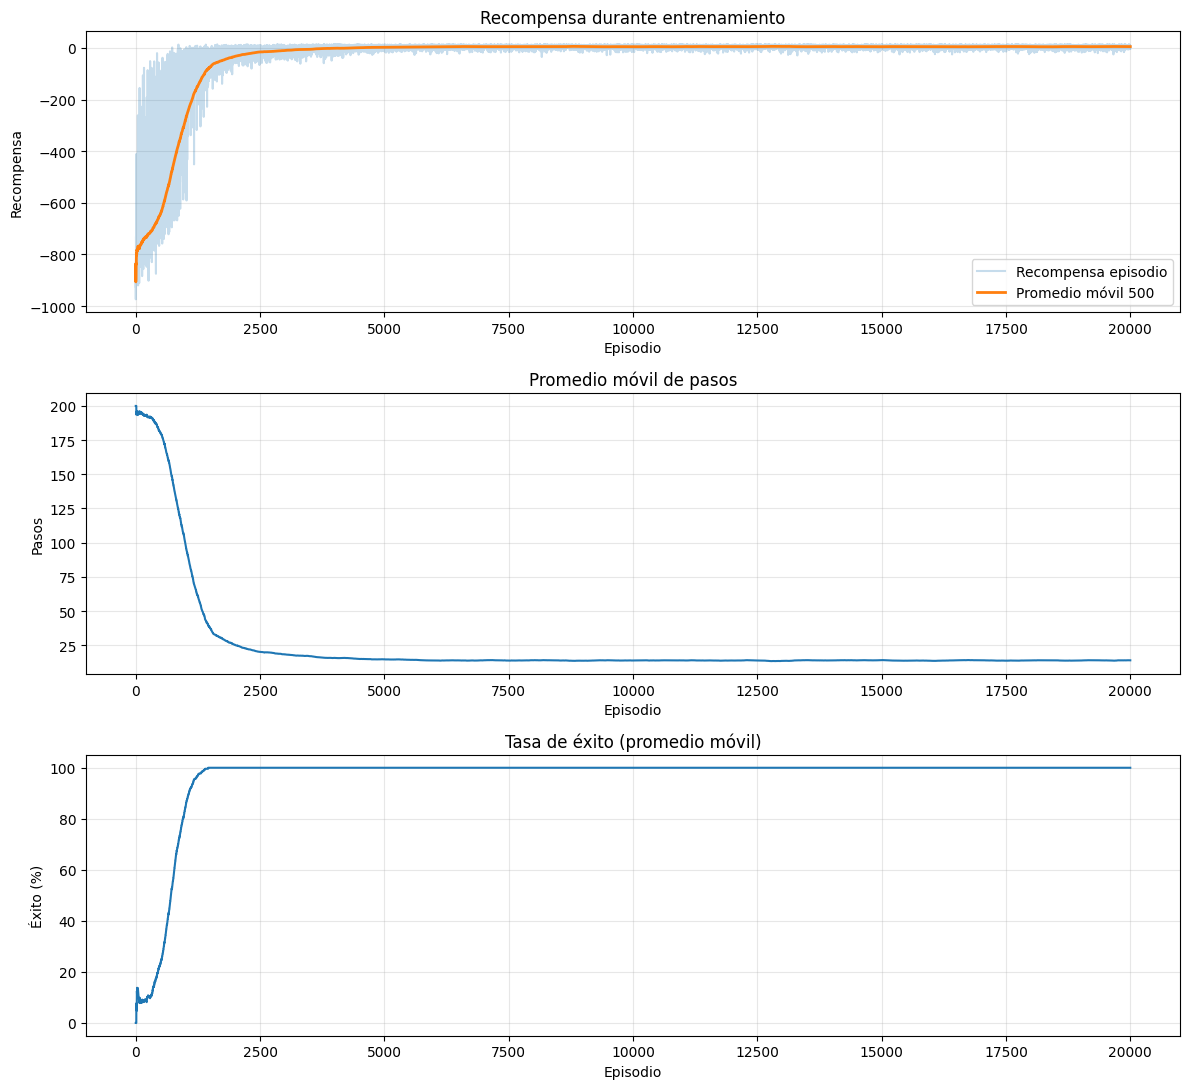

In [8]:
window = 500
reward_ma = pd.Series(rewards_ep).rolling(window, min_periods=1).mean()
steps_ma = pd.Series(steps_ep).rolling(window, min_periods=1).mean()
success_ma = pd.Series(success_ep).rolling(window, min_periods=1).mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 11))
axes[0].plot(rewards_ep, alpha=0.25, label="Recompensa episodio")
axes[0].plot(reward_ma, linewidth=2, label=f"Promedio móvil {window}")
axes[0].set_title("Recompensa durante entrenamiento"); axes[0].set_xlabel("Episodio"); axes[0].set_ylabel("Recompensa"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(steps_ma); axes[1].set_title("Promedio móvil de pasos"); axes[1].set_xlabel("Episodio"); axes[1].set_ylabel("Pasos"); axes[1].grid(alpha=.3)
axes[2].plot(success_ma*100); axes[2].set_title("Tasa de éxito (promedio móvil)"); axes[2].set_xlabel("Episodio"); axes[2].set_ylabel("Éxito (%)"); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Resumen de entrenamiento

In [14]:
training_df = pd.DataFrame({"Recompensa": rewards_ep, "Pasos": steps_ep, "Éxito": success_ep})
summary = pd.DataFrame({"Métrica": ["Recompensa media últimos 1.000", "Pasos medios últimos 1.000", "Éxito últimos 1.000 (%)"], "Valor": [training_df.Recompensa.tail(1000).mean(), training_df.Pasos.tail(1000).mean(), training_df.Éxito.tail(1000).mean()*100]})
display(summary.round(2))

,Métrica,Valor
0,Recompensa media últimos 1.000,5.32
1,Pasos medios últimos 1.000,13.86
2,Éxito últimos 1.000 (%),100.00


## 8. Evaluación del agente entrenado
En evaluación no se explora; se elige siempre la acción con mayor valor Q.

In [15]:
def evaluate_q(env, q_table, n=500, max_steps=200, seed=10000):
    rows=[]
    for i in range(n):
        state, info = env.reset(seed=seed+i)
        total, success = 0, 0
        for step in range(max_steps):
            action = int(np.argmax(q_table[state]))
            state, reward, terminated, truncated, info = env.step(action)
            total += reward
            if terminated:
                success=1; break
            if truncated: break
        rows.append((total, step+1, success))
    return pd.DataFrame(rows, columns=["Recompensa", "Pasos", "Éxito"])

trained_eval = evaluate_q(env, q_table)
display(trained_eval.head())
print(f"Recompensa promedio: {trained_eval.Recompensa.mean():.2f}")
print(f"Pasos promedio: {trained_eval.Pasos.mean():.2f}")
print(f"Tasa de éxito: {trained_eval.Éxito.mean()*100:.2f}%")

,Recompensa,Pasos,Éxito
0,9,12,1
1,10,11,1
2,8,13,1
3,7,14,1
4,5,16,1


Recompensa promedio: 7.92
Pasos promedio: 13.08
Tasa de éxito: 100.00%


## 9. Evaluación de agente aleatorio y comparación

In [16]:
def evaluate_random(env, n=500, max_steps=200, seed=20000):
    rows=[]
    for i in range(n):
        state, info = env.reset(seed=seed+i)
        total, success = 0, 0
        for step in range(max_steps):
            action = env.action_space.sample()
            state, reward, terminated, truncated, info = env.step(action)
            total += reward
            if terminated:
                success=1; break
            if truncated: break
        rows.append((total, step+1, success))
    return pd.DataFrame(rows, columns=["Recompensa", "Pasos", "Éxito"])

random_eval = evaluate_random(env)
comparison = pd.DataFrame({"Métrica": ["Recompensa promedio", "Pasos promedio", "Tasa de éxito (%)"], "Aleatorio": [random_eval.Recompensa.mean(), random_eval.Pasos.mean(), random_eval.Éxito.mean()*100], "Q-Learning": [trained_eval.Recompensa.mean(), trained_eval.Pasos.mean(), trained_eval.Éxito.mean()*100]})
display(comparison.round(2))

,Métrica,Aleatorio,Q-Learning
0,Recompensa promedio,-773.19,7.92
1,Pasos promedio,197.03,13.08
2,Tasa de éxito (%),3.60,100.00


## 10. Visualización comparativa

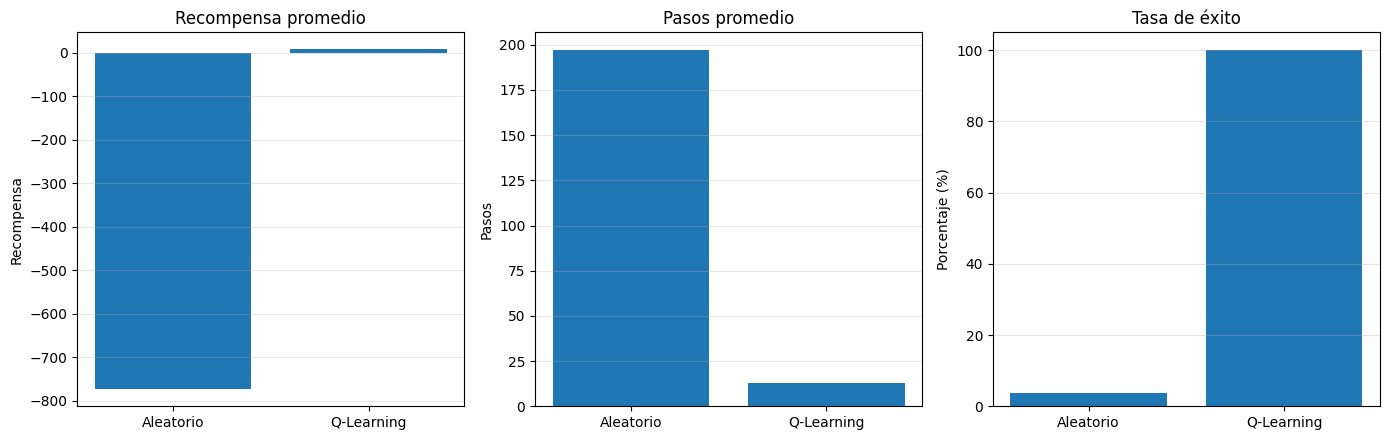

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
metrics = ["Recompensa", "Pasos", "Éxito"]
titles = ["Recompensa promedio", "Pasos promedio", "Tasa de éxito"]
for ax, metric, title in zip(axes, metrics, titles if False else ["Recompensa promedio", "Pasos promedio", "Tasa de éxito"]):
    values = [random_eval[metric].mean(), trained_eval[metric].mean()]
    if metric == "Éxito": values = [v*100 for v in values]
    ax.bar(["Aleatorio", "Q-Learning"], values)
    ax.set_title(title); ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("Recompensa"); axes[1].set_ylabel("Pasos"); axes[2].set_ylabel("Porcentaje (%)")
plt.tight_layout(); plt.show()

## 11. Visualizar una ejecución aprendida

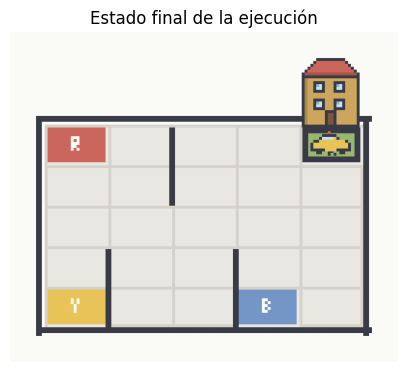

In [19]:
# Visualizar una ejecución aprendida

visual_env = gym.make("Taxi-v4", render_mode="rgb_array")

state, info = visual_env.reset(seed=123)
frames = []

for _ in range(100):
    action = int(np.argmax(q_table[state]))

    state, reward, terminated, truncated, info = visual_env.step(action)

    frames.append(visual_env.render())

    if terminated or truncated:
        break

visual_env.close()

if frames:
    plt.figure(figsize=(5, 5))
    plt.imshow(frames[-1])
    plt.axis("off")
    plt.title("Estado final de la ejecución")
    plt.show()

## 12. Interpretación de resultados
Esta celda muestra métricas reales de la ejecución para apoyar el análisis del informe. No se deben inventar ni modificar resultados.

In [20]:
print(f"Éxito Q-Learning: {trained_eval.Éxito.mean()*100:.2f}%")
print(f"Éxito aleatorio: {random_eval.Éxito.mean()*100:.2f}%")
print(f"Recompensa Q-Learning: {trained_eval.Recompensa.mean():.2f}")
print(f"Recompensa aleatoria: {random_eval.Recompensa.mean():.2f}")
print(f"Pasos Q-Learning: {trained_eval.Pasos.mean():.2f}")
print(f"Pasos aleatorios: {random_eval.Pasos.mean():.2f}")
if trained_eval.Éxito.mean() > random_eval.Éxito.mean():
    print("Interpretación preliminar: Q-Learning supera al agente aleatorio en tasa de éxito.")
else:
    print("Interpretación preliminar: revisar entrenamiento y parámetros; no superó al agente aleatorio en tasa de éxito.")

Éxito Q-Learning: 100.00%
Éxito aleatorio: 3.60%
Recompensa Q-Learning: 7.92
Recompensa aleatoria: -773.19
Pasos Q-Learning: 13.08
Pasos aleatorios: 197.03
Interpretación preliminar: Q-Learning supera al agente aleatorio en tasa de éxito.


## 13. Conclusiones (completar después de ejecutar)
 partir de los resultados obtenidos, se puede concluir que el algoritmo Q-Learning logró aprender una estrategia efectiva para resolver el entorno Taxi-v4. Durante el entrenamiento, el agente fue mejorando sus decisiones mediante la interacción con el entorno y el sistema de recompensas, hasta alcanzar una tasa de éxito del 100 % en los últimos 1.000 episodios.

En la evaluación realizada con 500 episodios, el agente entrenado obtuvo una recompensa promedio de 7.92 y necesitó aproximadamente 13.08 pasos para completar las tareas. Estos resultados muestran que logró aprender una estrategia eficiente, realizando menos acciones y evitando movimientos innecesarios.

La comparación con el agente aleatorio permitió evidenciar la diferencia entre actuar sin una estrategia aprendida y utilizar los conocimientos adquiridos durante el entrenamiento. El agente aleatorio obtuvo una recompensa promedio de -773.19, necesitó aproximadamente 197.03 pasos por episodio y alcanzó una tasa de éxito de apenas 3.60 %. Por el contrario, Q-Learning logró una tasa de éxito del 100 %, demostrando un desempeño considerablemente superior.

Este ejercicio permitió comprender de manera práctica cómo funciona el aprendizaje por refuerzo, especialmente la relación entre estados, acciones, recompensas y aprendizaje progresivo. También evidenció la importancia de parámetros como la tasa de aprendizaje, el factor de descuento y la exploración, los cuales influyen en la forma en que el agente descubre y mejora su estrategia.

Finalmente, aunque los resultados fueron positivos dentro del entorno simulado, es importante tener en cuenta que Taxi-v4 representa un problema simplificado. Una aplicación real, como la gestión de taxis o entregas logísticas, tendría que considerar factores adicionales como tráfico, distancias, tiempos de desplazamiento, disponibilidad de vehículos, seguridad y cambios en las condiciones del entorno. Por esta razón, los resultados obtenidos constituyen una base para comprender el potencial del aprendizaje por refuerzo, pero sería necesario realizar pruebas adicionales antes de aplicarlo en situaciones reales.

## 14. Referencias
Farama Foundation. (s. f.). *Gymnasium documentation: Taxi*. https://gymnasium.farama.org/

Sutton, R. S., & Barto, A. G. (2018). *Reinforcement learning: An introduction* (2nd ed.). MIT Press.

Este notebook es un ejercicio académico. Las cifras, gráficas y conclusiones deben obtenerse al ejecutar el código.